In [13]:
# STEP 1: IMPORT LIBRARIES AND LOAD CLEANED DATA

# Pandas is used for working with datasets
import pandas as pd

# Matplotlib is used to create graphs
import matplotlib.pyplot as plt

# Seaborn is used to create statistical visualizations
import seaborn as sns

# Load the cleaned La Liga dataset
laliga = pd.read_csv("../LinearRegression/laliga_cleaned.csv")

# Display the dataset dimensions
print("Dataset shape:", laliga.shape)

# Display the first five rows
display(laliga.head())

Dataset shape: (240, 20)


,rk,squad,mp,w,d,l,gf,ga,gd,pts,pts/mp,attendance,top_team_scorer,goalkeeper,notes,season,xg,xga,xgd,xgd/90
0,1,Barcelona,38,30,4,4,110,21,89,94,2.47,77632.0,Lionel Messi - 43,Claudio Bravo,→ Champions League via Champions League win,2014,NaN,NaN,NaN,NaN
1,2,Real Madrid,38,30,2,6,118,38,80,92,2.42,73545.0,Cristiano Ronaldo - 48,Iker Casillas,→ Champions League via league finish,2014,NaN,NaN,NaN,NaN
2,3,Atlético Madrid,38,23,9,6,67,29,38,78,2.05,46454.0,Antoine Griezmann - 22,Miguel Ángel Moyá,→ Champions League via league finish,2014,NaN,NaN,NaN,NaN
3,4,Valencia,38,22,11,5,70,32,38,77,2.03,43125.0,Daniel Parejo - 12,Diego Alves,→ Champions League via league finish,2014,NaN,NaN,NaN,NaN
4,5,Sevilla,38,23,7,8,71,45,26,76,2.00,30878.0,Carlos Bacca - 20,Sergio Rico,→ Champions League via Europa League win,2014,NaN,NaN,NaN,NaN


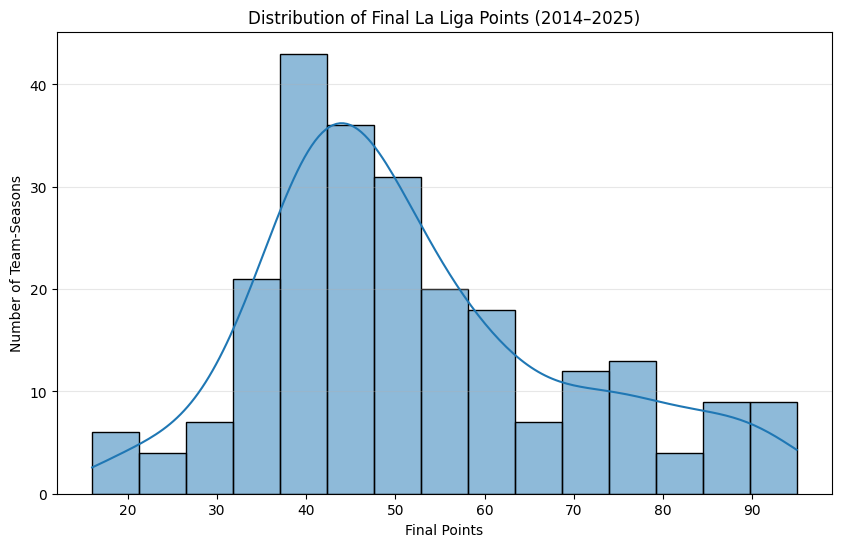

In [14]:
# STEP 2: DISTRIBUTION OF FINAL LA LIGA POINTS

# Create a figure with a width of 10 and height of 6
plt.figure(figsize=(10, 6))

# Create a histogram of final points
# bins=15 divides the points into 15 intervals
# kde=True adds a smooth curve showing the distribution
sns.histplot(
    data=laliga,
    x="pts",
    bins=15,
    kde=True
)

# Add a title and axis labels
plt.title("Distribution of Final La Liga Points (2014–2025)")
plt.xlabel("Final Points")
plt.ylabel("Number of Team-Seasons")

# Add grid lines to make the graph easier to read
plt.grid(axis="y", alpha=0.3)

# Display the graph
plt.show()

In [15]:
# STEP 3: SUMMARY STATISTICS FOR FINAL POINTS

# Calculate descriptive statistics for final points
print("Average points:", round(laliga["pts"].mean(), 2))
print("Median points:", laliga["pts"].median())
print("Minimum points:", laliga["pts"].min())
print("Maximum points:", laliga["pts"].max())

# Display additional statistics
display(laliga["pts"].describe())

Average points: 52.08
Median points: 48.0
Minimum points: 16
Maximum points: 95


count    240.00000
mean      52.07500
std       17.34159
min       16.00000
25%       41.00000
50%       48.00000
75%       61.00000
max       95.00000
Name: pts, dtype: float64

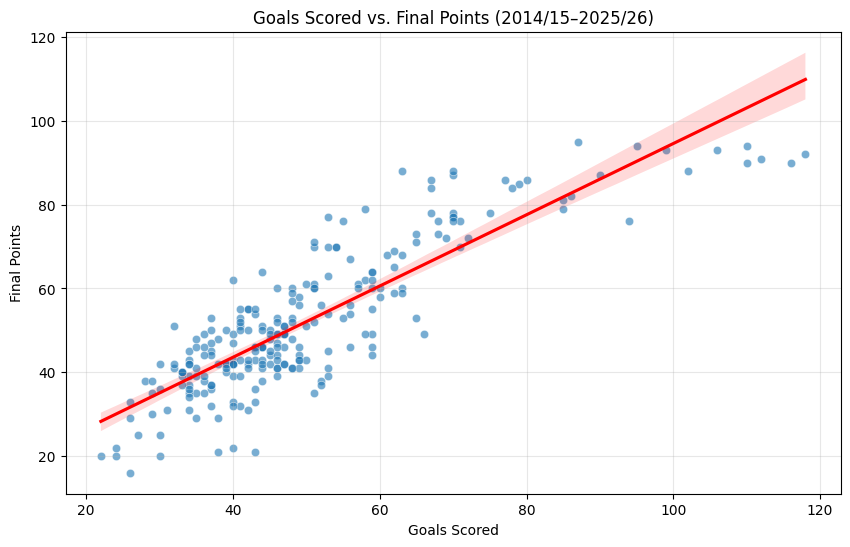

Correlation between goals scored and points: 0.862


In [16]:
# STEP 4: GOALS SCORED VS. FINAL POINTS

# Create a figure
plt.figure(figsize=(10, 6))

# Create a scatter plot
# Each dot represents one team in one season
sns.scatterplot(
    data=laliga,
    x="gf",       # Goals scored
    y="pts",      # Final league points
    alpha=0.6     # Make overlapping points easier to see
)

# Add a linear trend line
# scatter=False prevents drawing a second set of dots
sns.regplot(
    data=laliga,
    x="gf",
    y="pts",
    scatter=False,
    color="red"
)

# Add labels
plt.title("Goals Scored vs. Final Points (2014/15–2025/26)")
plt.xlabel("Goals Scored")
plt.ylabel("Final Points")

# Add grid lines
plt.grid(alpha=0.3)

# Display the graph
plt.show()

# Calculate the Pearson correlation coefficient
correlation = laliga["gf"].corr(laliga["pts"])

print("Correlation between goals scored and points:",
      round(correlation, 3))

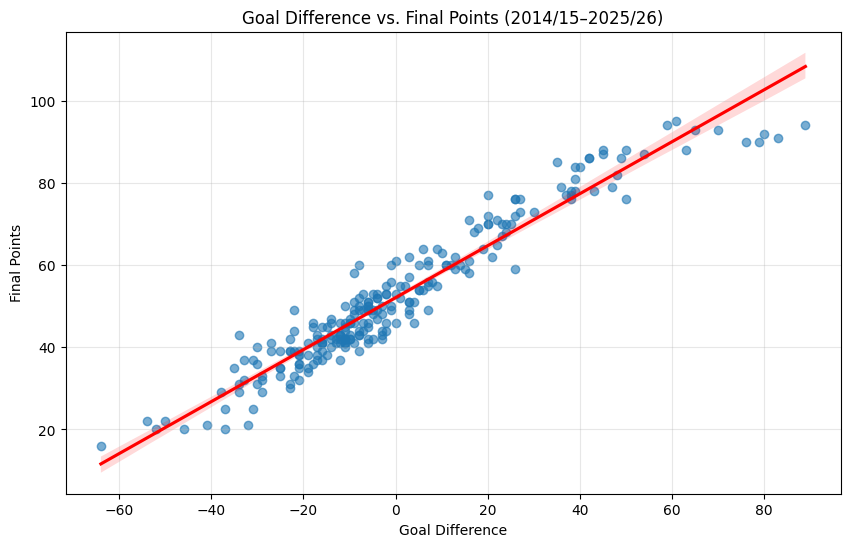

Goals Scored vs. Points: 0.862
Goal Difference vs. Points: 0.961


In [17]:
# STEP 5: GOAL DIFFERENCE VS. FINAL POINTS

# Create a figure
plt.figure(figsize=(10, 6))

# Plot goal difference against final points
# The regression line shows the overall linear relationship
sns.regplot(
    data=laliga,
    x="gd",
    y="pts",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

# Add title and labels
plt.title("Goal Difference vs. Final Points (2014/15–2025/26)")
plt.xlabel("Goal Difference")
plt.ylabel("Final Points")

# Add grid lines
plt.grid(alpha=0.3)

# Display the graph
plt.show()

# Compare both correlation coefficients
print("Goals Scored vs. Points:",
      round(laliga["gf"].corr(laliga["pts"]), 3))

print("Goal Difference vs. Points:",
      round(laliga["gd"].corr(laliga["pts"]), 3))

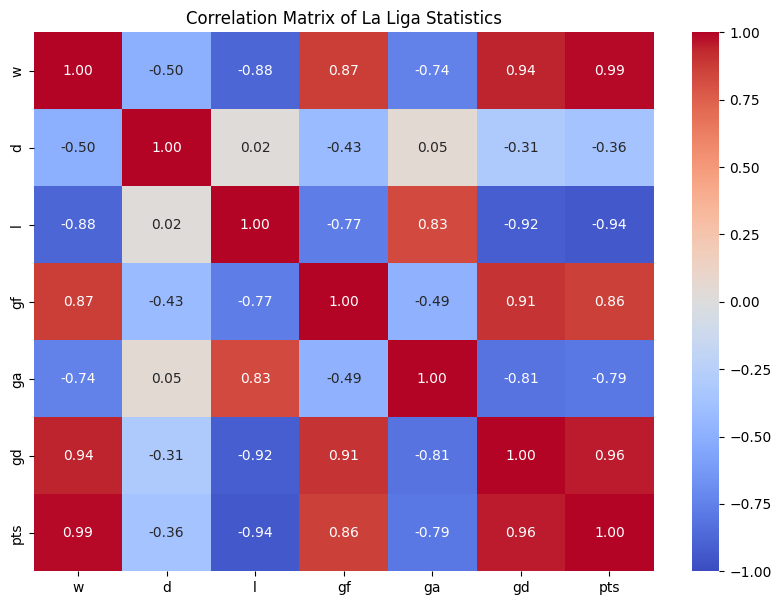

In [18]:
# STEP 6: CORRELATION MATRIX

# Select numerical football statistics
features = [
    "w",      # Wins
    "d",      # Draws
    "l",      # Losses
    "gf",     # Goals scored
    "ga",     # Goals conceded
    "gd",     # Goal difference
    "pts"     # Final points
]

# Calculate the Pearson correlation matrix
correlation_matrix = laliga[features].corr()

# Create a figure
plt.figure(figsize=(10, 7))

# Display correlations as a heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,       # Show correlation values
    fmt=".2f",        # Round values to two decimals
    cmap="coolwarm",  # Colour scheme
    vmin=-1,
    vmax=1
)

# Add title
plt.title("Correlation Matrix of La Liga Statistics")

# Display the graph
plt.show()

,squad,average_points,seasons_played
4,Barcelona,87.000000,12
25,Real Madrid,84.916667,12
3,Atlético Madrid,77.000000,12
31,Villarreal,61.000000,12
27,Sevilla,59.000000,12
2,Athletic Club,55.166667,12
26,Real Sociedad,55.000000,12
5,Betis,54.363636,11
29,Valencia,52.583333,12
13,Girona,50.000000,6


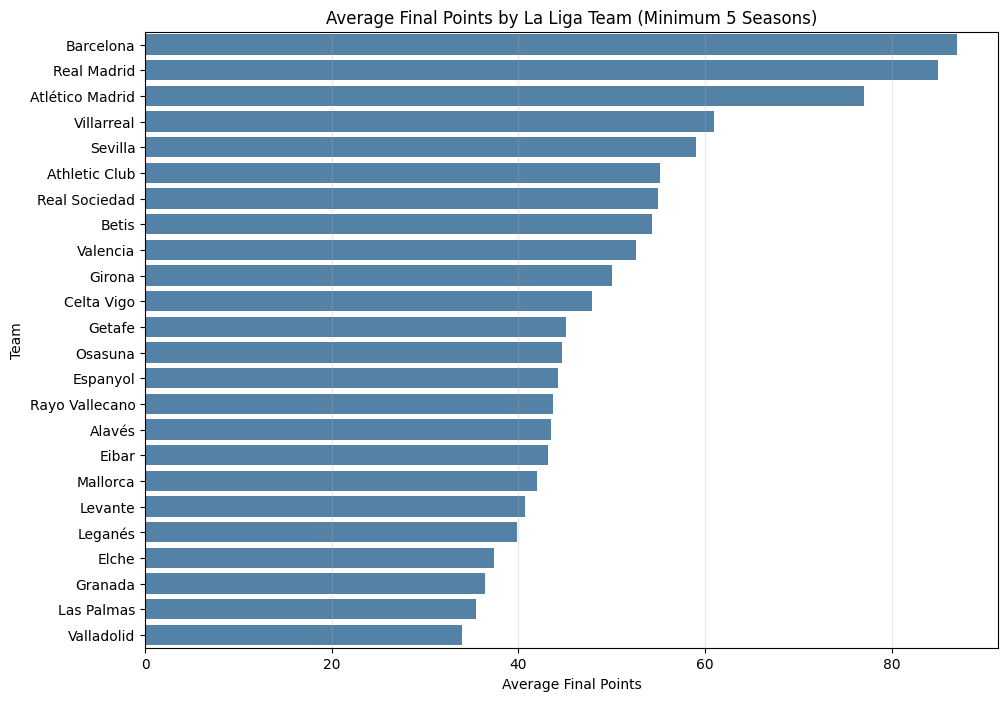

In [19]:
# STEP 7: AVERAGE POINTS BY TEAM

# Group the dataset by team name
# Calculate the average final points for each team
team_performance = (
    laliga.groupby("squad")
    .agg(
        average_points=("pts", "mean"),
        seasons_played=("season", "count")
    )
    .reset_index()
)

# Only include teams with at least 5 seasons
# This makes comparisons more meaningful
team_performance = team_performance[
    team_performance["seasons_played"] >= 5
]

# Sort teams by average points, highest first
team_performance = team_performance.sort_values(
    by="average_points",
    ascending=False
)

# Display the results
display(team_performance)

# Create a horizontal bar chart
plt.figure(figsize=(11, 8))

sns.barplot(
    data=team_performance,
    x="average_points",
    y="squad",
    color="steelblue"
)

plt.title("Average Final Points by La Liga Team (Minimum 5 Seasons)")
plt.xlabel("Average Final Points")
plt.ylabel("Team")
plt.grid(axis="x", alpha=0.3)

plt.show()